# Trabalho 1 — Introdução ao Processamento de Imagens (IPI - UnB)

**Universidade de Brasília (UnB) — Departamento de Ciência da Computação (CIC)**  
**Aluno:** Pedro Henrique Silva de Sousa
**Matricula:** 222001411

Este notebook apresenta a implementação completa em Python (`numpy`, `cv2`, `matplotlib`) adaptada do enunciado original em MATLAB, estruturada em:
- **Questão 1: Escalonamento Espacial e Super-Resolução (`FRUIT1` e `FRUIT2`)**
  - **1.1** Função `tam2(img, fator)` e função base `dobrar_tamanho_vizinho(img)` (repetição de linha/coluna via indexação NumPy para fatores $2\times$ e $8\times$).
  - **1.2** Função `tamm(img)` (interpolação $2\times$ por média horizontal nas linhas não vazias seguida de média vertical nas linhas vazias).
  - **1.3** Função `superres(img1, img2)` (combinação em grade intercalada $2\times$ e interpolação pela média dos vizinhos ortogonais).
- **Questão 2: Realce Radiométrico de Contraste (`car.png`, `crowd.png`, `university.png`)**
  - **2.1** Transformação Power-Law / Correção Gamma ($s = c \cdot r^\gamma$) com 2 valores $\gamma < 1$ e 2 valores $\gamma > 1$.
  - **2.2** Equalização Global de Histograma (`cv2.equalizeHist`), comparação visual e gráfico dedicado do Histograma + curva CDF antes e depois da equalização.
  - **2.3** Fundamentação teórica e análise comparativa dos resultados.

In [1]:
from pathlib import Path
from typing import Dict, Sequence, Tuple

import cv2
import matplotlib.pyplot as plt
import numpy as np

# Configuração padrão de exibição do Matplotlib
plt.rcParams["figure.dpi"] = 120
plt.rcParams["axes.titlesize"] = 11

---
## Questão 1: Escalonamento e Super-Resolução (`FRUIT1` e `FRUIT2`)

### 1.1 Função `tam2(img, fator)` — Escalonamento por Repetição de Linha e Coluna
A função base `dobrar_tamanho_vizinho(img)` dobra a dimensão espacial ($2\times$) repetindo a linha e a coluna imediatamente anteriores exclusivamente via indexação de fatias (*slicing*) do NumPy (`saida[0::2, 0::2] = img`, `saida[0::2, 1::2] = img`, `saida[1::2, :] = saida[0::2, :]`), sem utilizar `cv2.resize`. A função `tam2(img, fator)` chama recursivamente a função base $\log_2(\text{fator})$ vezes até atingir o fator desejado ($2\times$ e $8\times$).

In [2]:
def dobrar_tamanho_vizinho(img: np.ndarray) -> np.ndarray:
    """
    Função base que dobra a dimensão espacial (2x) de uma imagem (2D ou 3D RGB)
    repetindo a linha e a coluna anterior exclusivamente via indexação do NumPy,
    sem utilizar cv2.resize.
    """
    altura, largura = img.shape[:2]
    canais = img.shape[2:]

    saida = np.zeros((2 * altura, 2 * largura, *canais), dtype=img.dtype)

    # Linhas pares recebem os pixels originais nas colunas pares
    # e repetem a coluna anterior nas colunas ímpares:
    saida[0::2, 0::2] = img
    saida[0::2, 1::2] = img

    # Linhas ímpares repetem integralmente a linha par imediatamente anterior:
    saida[1::2, :] = saida[0::2, :]

    return saida


def tam2(img: np.ndarray, fator: int) -> np.ndarray:
    """
    Aumenta o número de linhas e colunas da imagem pelo 'fator' especificado (par >= 2)
    chamando recursivamente a função base `dobrar_tamanho_vizinho`.
    """
    if not isinstance(fator, (int, np.integer)) or fator < 2 or fator % 2 != 0:
        raise ValueError(f"O parâmetro 'fator' deve ser um inteiro par >= 2 (recebido: {fator}).")

    # Caso base: fator == 2
    if fator == 2:
        return dobrar_tamanho_vizinho(img)

    # Para potências de 2 (ex.: 4, 8), aplica recursivamente dobrar_tamanho_vizinho
    if (fator & (fator - 1)) == 0:
        return tam2(dobrar_tamanho_vizinho(img), fator // 2)

    # Caso geral para qualquer número par via indexação de fatias
    altura, largura = img.shape[:2]
    idx_linhas = np.arange(altura * fator) // fator
    idx_colunas = np.arange(largura * fator) // fator
    return img[idx_linhas[:, None], idx_colunas[None, :]]


# Teste de validação 1.1 com a matriz 2x2 do enunciado
matriz_exemplo = np.array([[10, 12], [5, 7]], dtype=np.uint8)
print("Matriz Original (2x2):\n", matriz_exemplo)
print("\ntam2(matriz, 2) (4x4):\n", tam2(matriz_exemplo, 2))

Matriz Original (2x2):
 [[10 12]
 [ 5  7]]

tam2(matriz, 2) (4x4):
 [[10 10 12 12]
 [10 10 12 12]
 [ 5  5  7  7]
 [ 5  5  7  7]]


### 1.2 Função `tamm(img)` — Escalonamento $2\times$ por Média de Vizinhos
A função `tamm(img)` amplia a imagem em $2\times$ em duas etapas sequenciais:
1. Preenche os pixels intermediários nas linhas **não vazias** (linhas pares na indexação base-0) pela **média horizontal** dos vizinhos laterais (`0::2, 1:-1:2`), repetindo a última coluna na borda direita (`0::2, -1`).
2. Preenche as linhas **vazias** (linhas ímpares na indexação base-0) pela **média vertical** das linhas superior e inferior já preenchidas (`1:-1:2, :`), repetindo a última linha na borda inferior (`-1, :`).

O arredondamento $\lfloor x + 0,5 \rfloor$ (`_arredondar_matlab`) reproduz o comportamento exato da aritmética inteira `uint8` do MATLAB, onde a matriz `[[10, 12], [5, 7]]` se torna `[[10, 11, 12, 12], [8, 9, 10, 10], [5, 6, 7, 7], [5, 6, 7, 7]]`.

In [3]:
def _arredondar_matlab(valores: np.ndarray) -> np.ndarray:
    """Arredondamento 'round half away from zero' padrão do uint8 no MATLAB."""
    return np.floor(valores + 0.5)


def tamm(img: np.ndarray) -> np.ndarray:
    """
    Aumenta a imagem em 2x preenchendo primeiro os pixels intermediários das linhas
    não vazias pela média horizontal e, em seguida, preenchendo as linhas vazias
    pela média vertical (tratando as bordas direita e inferior por repetição).
    """
    altura, largura = img.shape[:2]
    canais = img.shape[2:]

    saida = np.zeros((2 * altura, 2 * largura, *canais), dtype=np.float64)

    # Aloca os pixels originais nas linhas pares e colunas pares
    saida[0::2, 0::2] = img.astype(np.float64)

    # 1ª Etapa (Pixels vermelhos no enunciado): média horizontal nas linhas não vazias (0::2)
    saida[0::2, 1:-1:2] = _arredondar_matlab(
        (saida[0::2, 0:-2:2] + saida[0::2, 2::2]) / 2.0
    )
    saida[0::2, -1] = saida[0::2, -2]  # Repetição na borda direita

    # 2ª Etapa (Pixels azuis no enunciado): média vertical nas linhas vazias (1::2)
    saida[1:-1:2, :] = _arredondar_matlab(
        (saida[0:-2:2, :] + saida[2::2, :]) / 2.0
    )
    saida[-1, :] = saida[-2, :]  # Repetição na borda inferior

    if np.issubdtype(img.dtype, np.integer):
        info = np.iinfo(img.dtype)
        saida = np.clip(saida, info.min, info.max)

    return saida.astype(img.dtype)


# Teste de validação 1.2 com a matriz 2x2 do enunciado
resultado_tamm = tamm(matriz_exemplo)
print("tamm(matriz) (4x4):\n", resultado_tamm)

tamm(matriz) (4x4):
 [[10 11 12 12]
 [ 8  9 10 10]
 [ 5  6  7  7]
 [ 5  6  7  7]]


### 1.3 Função `superres(img1, img2)` — Super-Resolução em Grade $2\times$
Convertendo a indexação base-1 do MATLAB para a indexação base-0 do Python:
- As posições ímpares do MATLAB `(1,1), (1,3), (3,3)...` correspondem aos **índices pares `(0::2, 0::2)`** no Python, onde é alocada `img1`.
- As posições pares do MATLAB `(2,2), (2,4), (4,4)...` correspondem aos **índices ímpares `(1::2, 1::2)`** no Python, onde é alocada `img2`.
- Os pixels restantes nas posições `(0::2, 1::2)` e `(1::2, 0::2)` são interpolados pela média aritmética dos seus vizinhos ortogonais disponíveis (4 no interior, 3 nas bordas e 2 nos cantos).

In [4]:
def tam2_ajustar_dimensao(img: np.ndarray, altura_alvo: int, largura_alvo: int) -> np.ndarray:
    """Compatibiliza a dimensão espacial para (altura_alvo, largura_alvo) via indexação NumPy."""
    h_orig, w_orig = img.shape[:2]
    idx_y = (np.arange(altura_alvo) * h_orig) // altura_alvo
    idx_x = (np.arange(largura_alvo) * w_orig) // largura_alvo
    return img[idx_y[:, None], idx_x[None, :]]


def superres(img1: np.ndarray, img2: np.ndarray) -> np.ndarray:
    """
    Combina img1 e img2 em uma grade 2x maior:
      - img1 nos índices pares (0::2, 0::2)
      - img2 nos índices ímpares (1::2, 1::2)
      - pixels restantes (0::2, 1::2) e (1::2, 0::2) pela média dos vizinhos ortogonais.
    """
    if img1.shape != img2.shape:
        img2 = tam2_ajustar_dimensao(img2, img1.shape[0], img1.shape[1])

    altura, largura = img1.shape[:2]
    canais = img1.shape[2:]

    saida = np.zeros((2 * altura, 2 * largura, *canais), dtype=np.float64)

    f_img1 = img1.astype(np.float64)
    f_img2 = img2.astype(np.float64)
    saida[0::2, 0::2] = f_img1
    saida[1::2, 1::2] = f_img2

    # Interpola (0::2, 1::2) [linhas pares, colunas ímpares]
    soma_par_impar = f_img1 + f_img2
    cont_par_impar = np.full((altura, largura, *(1 for _ in canais)), 2.0, dtype=np.float64)
    soma_par_impar[:, :-1] += f_img1[:, 1:]
    cont_par_impar[:, :-1] += 1.0
    soma_par_impar[1:, :] += f_img2[:-1, :]
    cont_par_impar[1:, :] += 1.0
    saida[0::2, 1::2] = _arredondar_matlab(soma_par_impar / cont_par_impar)

    # Interpola (1::2, 0::2) [linhas ímpares, colunas pares]
    soma_impar_par = f_img1 + f_img2
    cont_impar_par = np.full((altura, largura, *(1 for _ in canais)), 2.0, dtype=np.float64)
    soma_impar_par[:-1, :] += f_img1[1:, :]
    cont_impar_par[:-1, :] += 1.0
    soma_impar_par[:, 1:] += f_img2[:, :-1]
    cont_impar_par[:, 1:] += 1.0
    saida[1::2, 0::2] = _arredondar_matlab(soma_impar_par / cont_impar_par)

    if np.issubdtype(img1.dtype, np.integer):
        info = np.iinfo(img1.dtype)
        saida = np.clip(saida, info.min, info.max)

    return saida.astype(img1.dtype)


def carregar_imagens_fruit(img_dir: str | Path = "img") -> Tuple[np.ndarray, np.ndarray]:
    """Carrega FRUIT1 e FRUIT2 em formato RGB."""
    pasta = Path(img_dir)
    extensoes = {".jpg", ".jpeg", ".png", ".bmp"}

    def _buscar(stem_alvo: str) -> Path:
        for arq in sorted(pasta.iterdir()):
            if arq.is_file() and arq.stem.lower() == stem_alvo.lower() and arq.suffix.lower() in extensoes:
                return arq
        raise FileNotFoundError(f"{stem_alvo} não encontrado em {pasta}")

    rgb1 = cv2.cvtColor(cv2.imread(str(_buscar("FRUIT1")), cv2.IMREAD_COLOR), cv2.COLOR_BGR2RGB)
    rgb2 = cv2.cvtColor(cv2.imread(str(_buscar("FRUIT2")), cv2.IMREAD_COLOR), cv2.COLOR_BGR2RGB)
    if rgb1.shape[:2] != rgb2.shape[:2]:
        rgb2 = tam2_ajustar_dimensao(rgb2, rgb1.shape[0], rgb1.shape[1])
    return rgb1, rgb2


# Teste de validação 1.3 com matrizes 2x2
img1_teste = np.array([[10, 12], [5, 7]], dtype=np.uint8)
img2_teste = np.array([[11, 13], [6, 8]], dtype=np.uint8)
print("superres(img1_teste, img2_teste) (4x4):\n", superres(img1_teste, img2_teste))

superres(img1_teste, img2_teste) (4x4):
 [[10 11 12 13]
 [ 9 11 11 13]
 [ 5  7  7  9]
 [ 6  6  7  8]]


FRUIT1 original      : (447, 447, 3)
1.1 tam2(FRUIT1, 2)  : (894, 894, 3)
1.1 tam2(FRUIT1, 8)  : (3576, 3576, 3)
1.2 tamm(FRUIT1)     : (894, 894, 3)
1.3 superres(F1, F2) : (894, 894, 3)


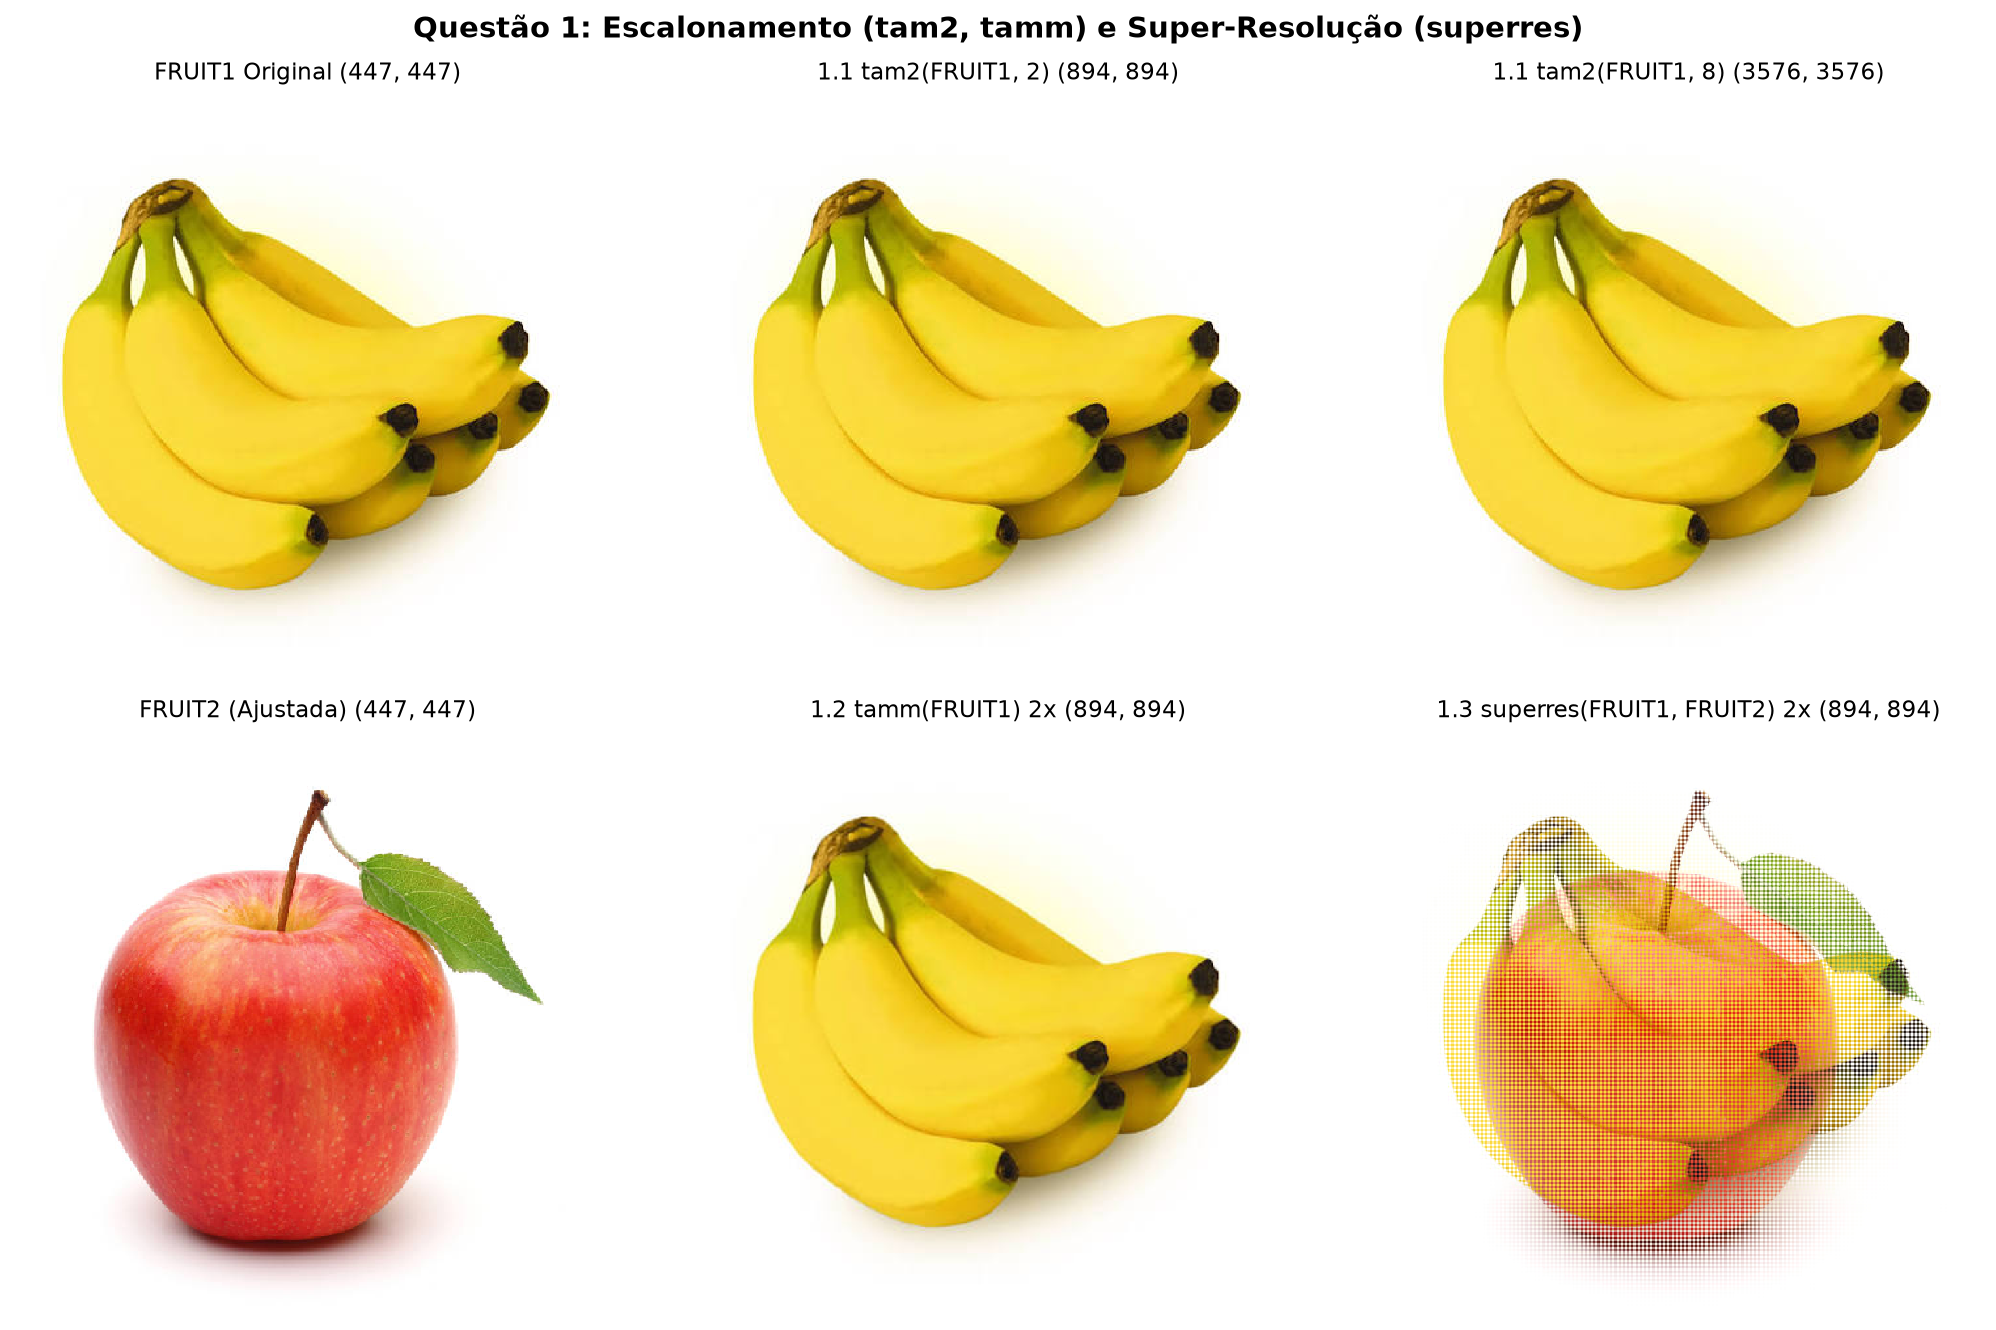

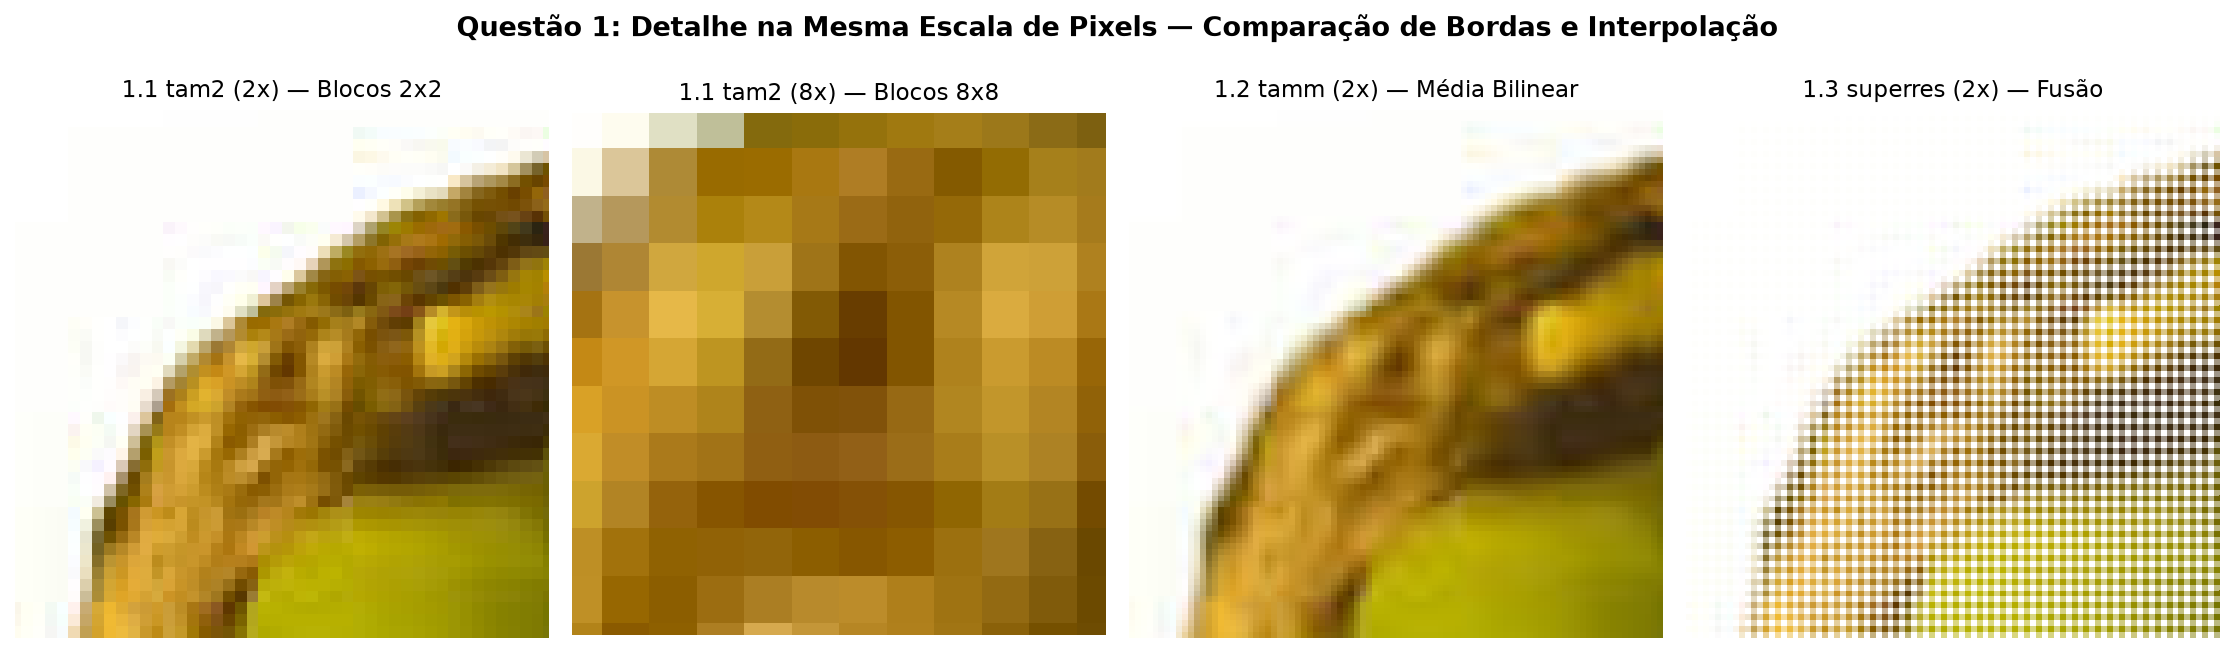

In [5]:
# Execução da Questão 1 nas imagens FRUIT1 e FRUIT2
fruit1, fruit2 = carregar_imagens_fruit("img")

fruit1_tam2_2x = tam2(fruit1, 2)
fruit1_tam2_8x = tam2(fruit1, 8)
fruit1_tamm_2x = tamm(fruit1)
fruit_superres_2x = superres(fruit1, fruit2)

print(f"FRUIT1 original      : {fruit1.shape}")
print(f"1.1 tam2(FRUIT1, 2)  : {fruit1_tam2_2x.shape}")
print(f"1.1 tam2(FRUIT1, 8)  : {fruit1_tam2_8x.shape}")
print(f"1.2 tamm(FRUIT1)     : {fruit1_tamm_2x.shape}")
print(f"1.3 superres(F1, F2) : {fruit_superres_2x.shape}")

# Visualização Global da Questão 1
fig, eixos = plt.subplots(2, 3, figsize=(14, 9))
fig.suptitle("Questão 1: Escalonamento (tam2, tamm) e Super-Resolução (superres)", fontsize=14, fontweight="bold")

painel_q1 = [
    (eixos[0, 0], fruit1, f"FRUIT1 Original {fruit1.shape[:2]}"),
    (eixos[0, 1], fruit1_tam2_2x, f"1.1 tam2(FRUIT1, 2) {fruit1_tam2_2x.shape[:2]}"),
    (eixos[0, 2], fruit1_tam2_8x, f"1.1 tam2(FRUIT1, 8) {fruit1_tam2_8x.shape[:2]}"),
    (eixos[1, 0], fruit2, f"FRUIT2 (Ajustada) {fruit2.shape[:2]}"),
    (eixos[1, 1], fruit1_tamm_2x, f"1.2 tamm(FRUIT1) 2x {fruit1_tamm_2x.shape[:2]}"),
    (eixos[1, 2], fruit_superres_2x, f"1.3 superres(FRUIT1, FRUIT2) 2x {fruit_superres_2x.shape[:2]}"),
]
for ax, im, titulo in painel_q1:
    ax.imshow(im, interpolation="nearest")
    ax.set_title(titulo)
    ax.axis("off")

plt.tight_layout()
plt.show()

# Visualização em Detalhe (Zoom na mesma escala de pixels de saída)
h2, w2 = fruit1_tam2_2x.shape[:2]
r0, r1 = int(h2 * 0.14), int(h2 * 0.24)
c0, c1 = int(w2 * 0.17), int(w2 * 0.27)
alt_rec, larg_rec = r1 - r0, c1 - c0
rc_8x, cc_8x = int(((r0 + r1) / 2.0) * 4), int(((c0 + c1) / 2.0) * 4)
r0_8x, r1_8x = rc_8x - alt_rec // 2, rc_8x + alt_rec // 2
c0_8x, c1_8x = cc_8x - larg_rec // 2, cc_8x + larg_rec // 2

fig_z, eixos_z = plt.subplots(1, 4, figsize=(15, 4.2))
fig_z.suptitle("Questão 1: Detalhe na Mesma Escala de Pixels — Comparação de Bordas e Interpolação", fontsize=13, fontweight="bold", y=1.03)

recortes = [
    (fruit1_tam2_2x[r0:r1, c0:c1], "1.1 tam2 (2x) — Blocos 2x2"),
    (fruit1_tam2_8x[r0_8x:r1_8x, c0_8x:c1_8x], "1.1 tam2 (8x) — Blocos 8x8"),
    (fruit1_tamm_2x[r0:r1, c0:c1], "1.2 tamm (2x) — Média Bilinear"),
    (fruit_superres_2x[r0:r1, c0:c1], "1.3 superres (2x) — Fusão"),
]
for ax, (rec, titulo) in zip(eixos_z, recortes):
    ax.imshow(rec, interpolation="nearest")
    ax.set_title(titulo)
    ax.axis("off")

plt.tight_layout()
plt.show()

---
## Questão 2: Realce de Contraste (`car.png`, `crowd.png`, `university.png`)

### 2.1 Transformação Power-Law (Correção Gamma)
A transformação Power-Law é definida por:
$$s = c \cdot r^\gamma$$
onde $r \in [0, 1]$ é a intensidade normalizada de entrada, $c = 1,0$ é a constante de escala e $\gamma > 0$ controla a curvatura do mapeamento:
- **$\gamma < 1$ (testado com $0,4$ e $0,6$):** expande os tons escuros e clareia imagens subexpostas.
- **$\gamma > 1$ (testado com $1,5$ e $2,5$):** comprime os tons escuros e expande os tons claros.

Estatísticas das imagens originais da Questão 2:
  car.png        : shape=(338, 600), min= 93, max=185, média=128.69, std=18.40
  crowd.png      : shape=(600, 800), min=  0, max=255, média= 29.96, std=35.40
  university.png : shape=(300, 399), min=  0, max=255, média= 14.84, std=11.80


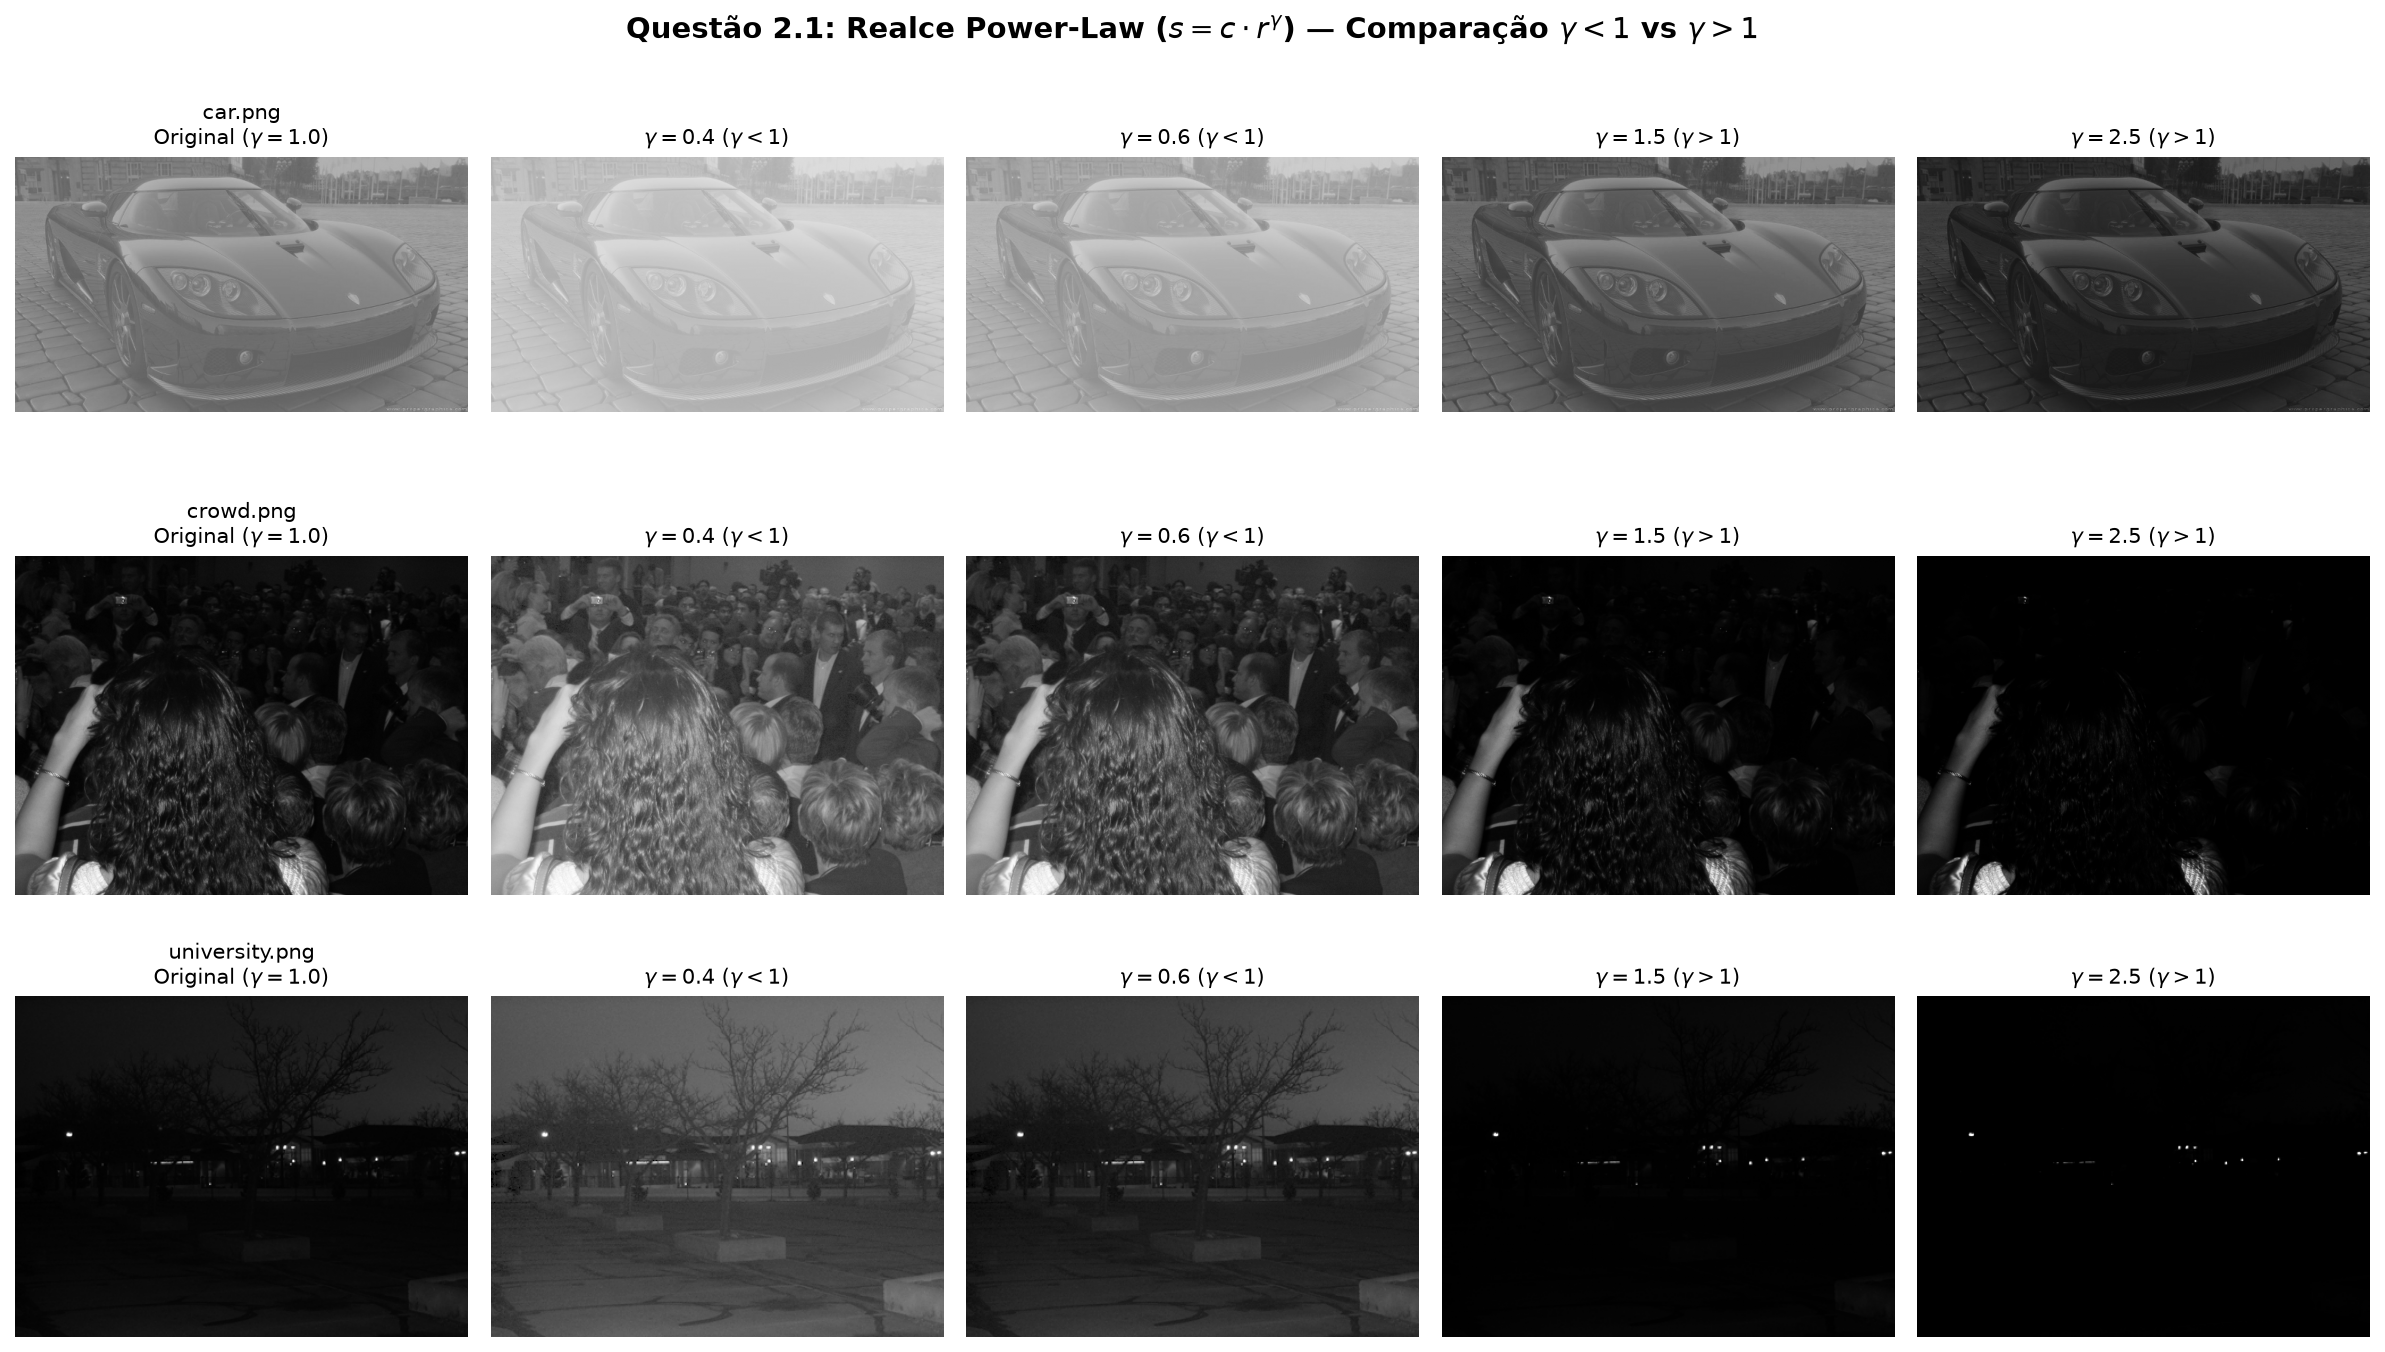

In [6]:
def correcao_gamma(
    img: np.ndarray,
    gamma: float,
    c: float = 1.0,
    usar_lut: bool = True,
) -> np.ndarray:
    """
    Aplica a correção gamma (s = c * r^gamma) utilizando Look-Up Table (cv2.LUT)
    ou normalização direta da matriz no intervalo [0, 1].
    """
    if gamma <= 0:
        raise ValueError("O parâmetro 'gamma' deve ser positivo.")

    if usar_lut and img.dtype == np.uint8:
        r_lut = np.arange(256, dtype=np.float64) / 255.0
        s_lut = np.clip(c * (r_lut ** gamma) * 255.0, 0.0, 255.0)
        tabela_lut = np.round(s_lut).astype(np.uint8)
        return cv2.LUT(img, tabela_lut)

    r_norm = img.astype(np.float64) / 255.0
    s_norm = c * np.power(r_norm, gamma)
    return np.clip(np.round(s_norm * 255.0), 0.0, 255.0).astype(np.uint8)


# Carregamento das três imagens da Questão 2
nomes_q2 = ("car.png", "crowd.png", "university.png")
imagens_q2: Dict[str, np.ndarray] = {}

print("Estatísticas das imagens originais da Questão 2:")
for nome in nomes_q2:
    img = cv2.imread(str(Path("img") / nome), cv2.IMREAD_GRAYSCALE)
    imagens_q2[nome] = img
    print(f"  {nome:15s}: shape={img.shape}, min={img.min():3d}, max={img.max():3d}, média={img.mean():6.2f}, std={img.std():5.2f}")

# Teste de 2 valores com gamma < 1 (0.4, 0.6) e 2 valores com gamma > 1 (1.5, 2.5)
gammas_teste = (0.4, 0.6, 1.5, 2.5)
fig, eixos = plt.subplots(len(imagens_q2), 1 + len(gammas_teste), figsize=(16, 9.5))
fig.suptitle(r"Questão 2.1: Realce Power-Law ($s = c \cdot r^\gamma$) — Comparação $\gamma < 1$ vs $\gamma > 1$", fontsize=14, fontweight="bold")

for i, (nome, img_orig) in enumerate(imagens_q2.items()):
    eixos[i, 0].imshow(img_orig, cmap="gray", vmin=0, vmax=255)
    eixos[i, 0].set_title(rf"{nome}" + "\n" + r"Original ($\gamma = 1.0$)", fontsize=10)
    eixos[i, 0].axis("off")

    for j, g in enumerate(gammas_teste, start=1):
        img_g = correcao_gamma(img_orig, gamma=g, usar_lut=True)
        tipo_g = r"\gamma < 1" if g < 1.0 else r"\gamma > 1"
        eixos[i, j].imshow(img_g, cmap="gray", vmin=0, vmax=255)
        eixos[i, j].set_title(rf"$\gamma = {g}$ (${tipo_g}$)", fontsize=10)
        eixos[i, j].axis("off")

plt.tight_layout()
plt.show()

### 2.2 Equalização de Histograma e Curva CDF (Função de Distribuição Acumulada)
Utiliza-se `cv2.equalizeHist` nas três imagens, comparando-as visualmente com as imagens originais e com o melhor resultado de correção $\gamma$. Em seguida, plota-se o gráfico dedicado contendo o **Histograma** e a **curva CDF normalizada** antes e depois da equalização para `car.png`.

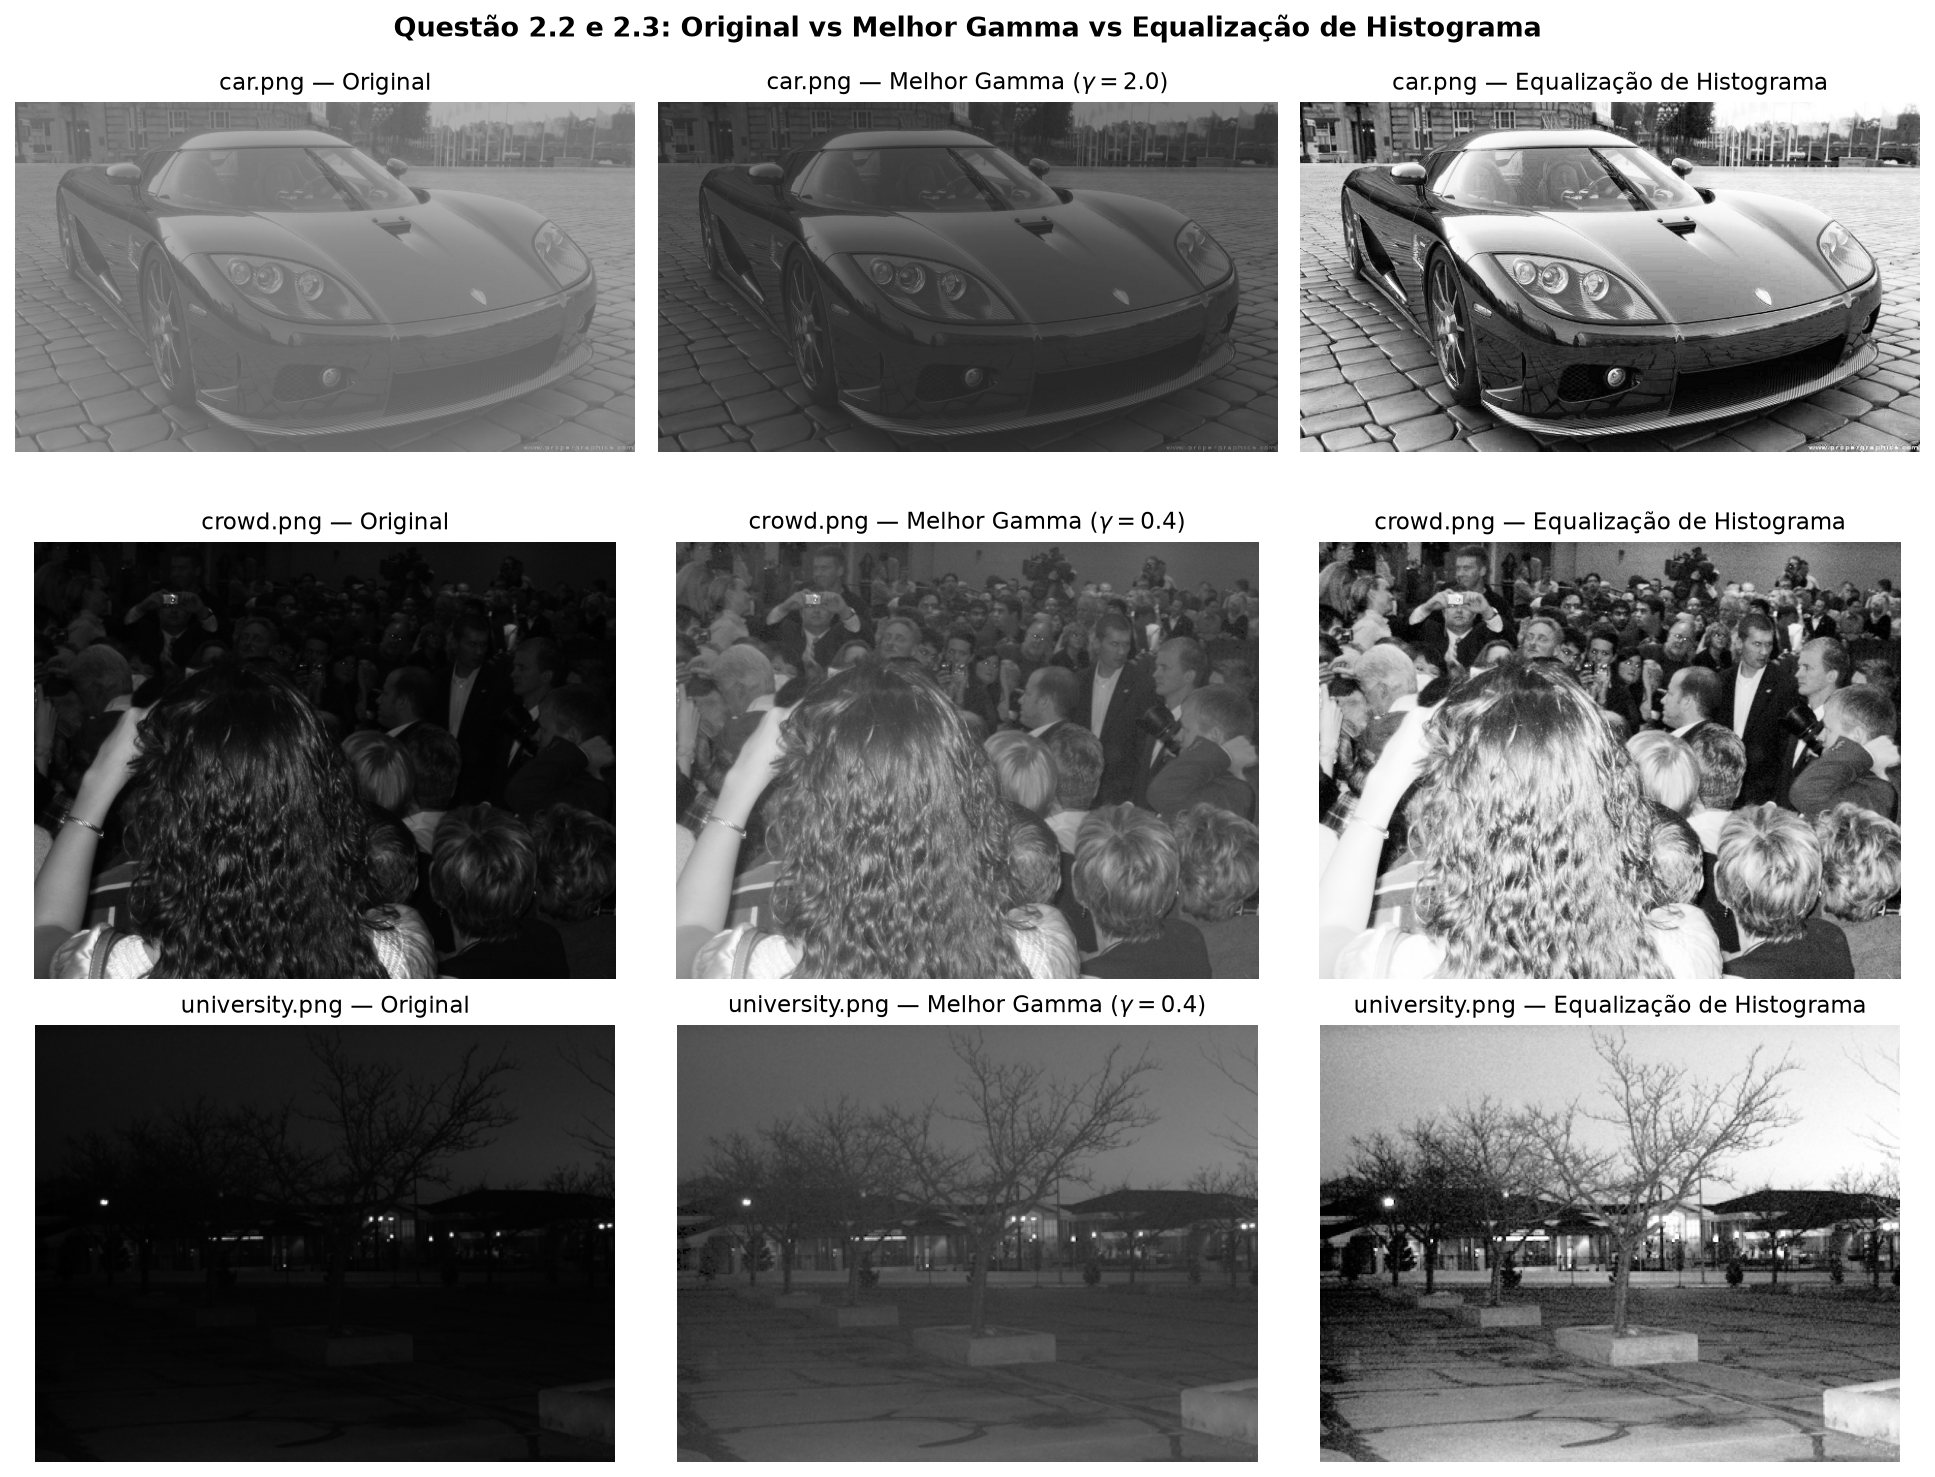

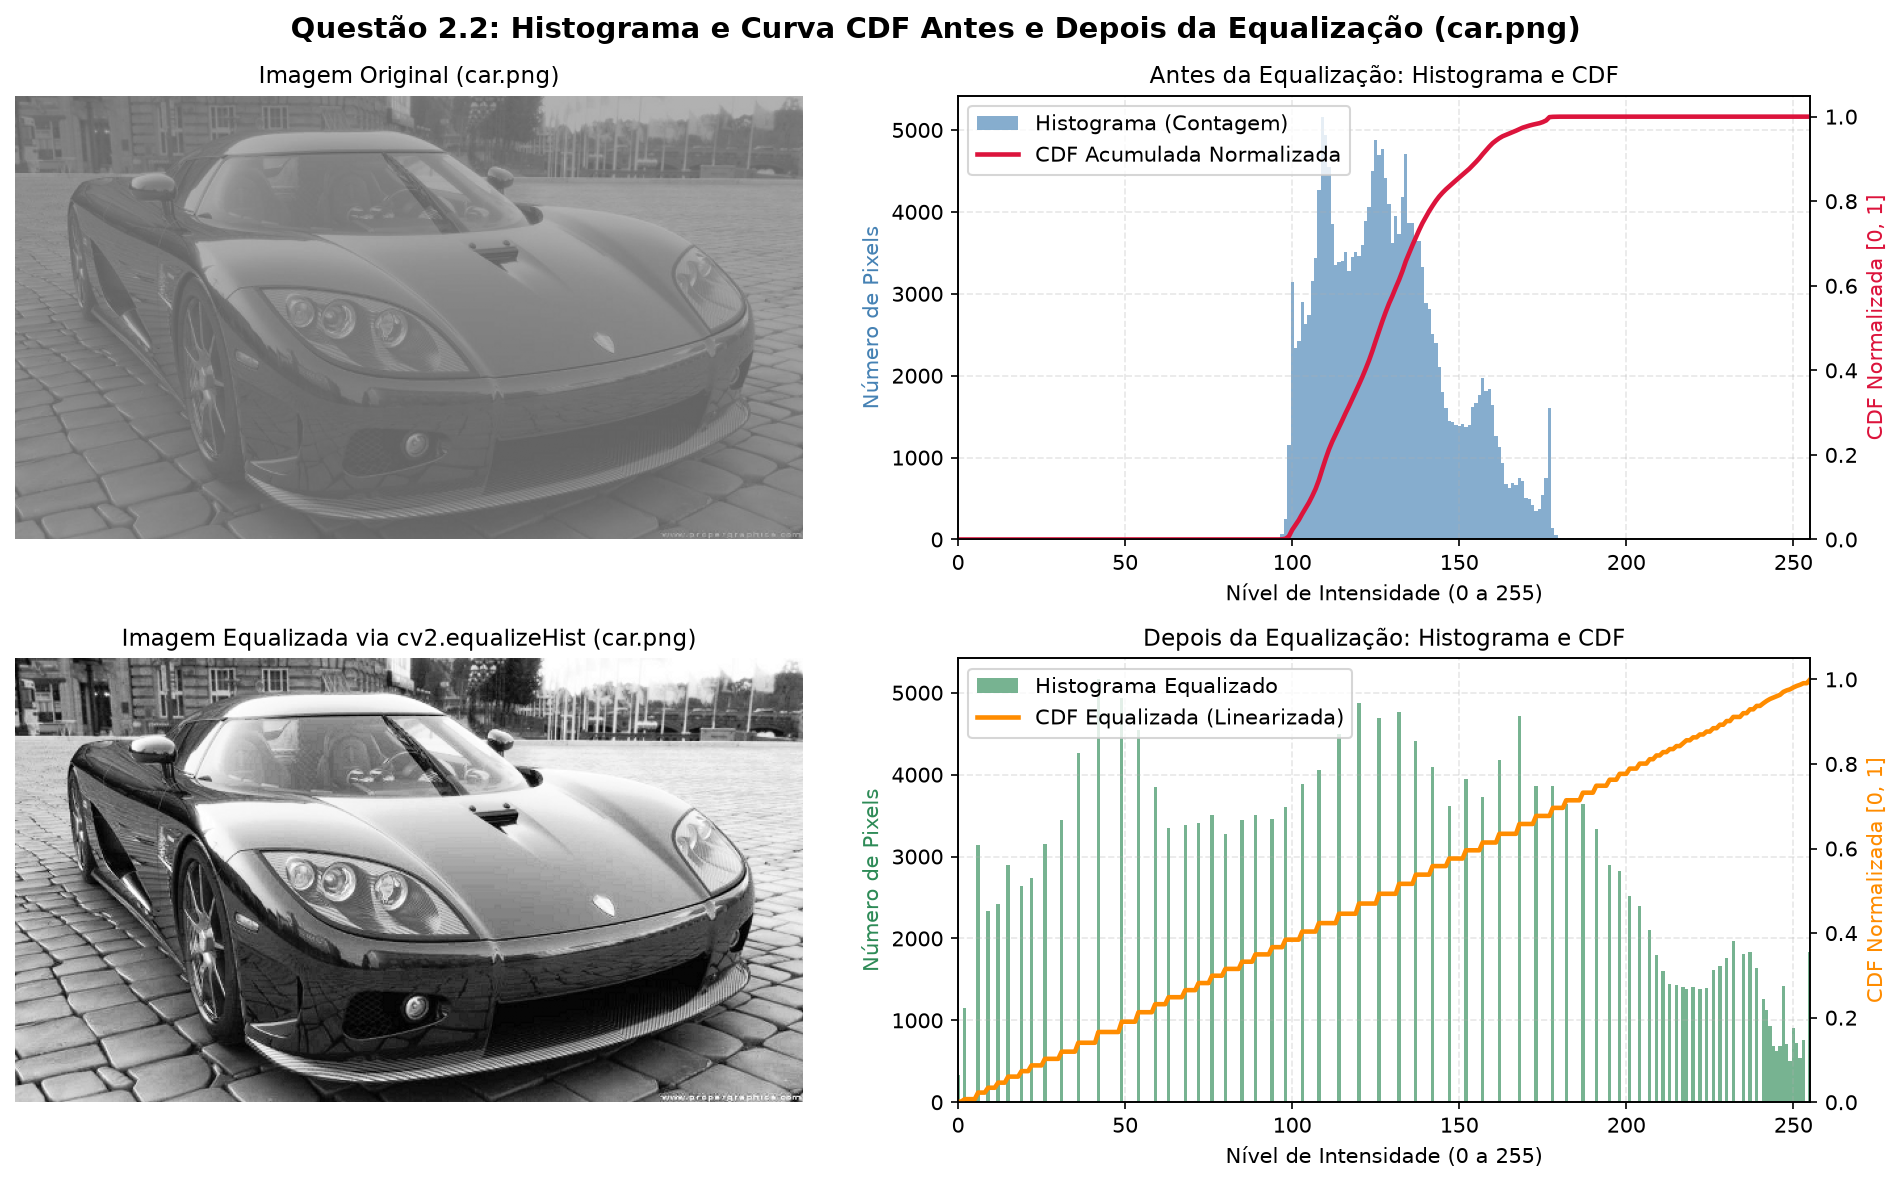

In [7]:
def equalizar_histograma(img: np.ndarray) -> np.ndarray:
    """Aplica equalização global de histograma via cv2.equalizeHist."""
    return cv2.equalizeHist(img)


def calcular_histograma_e_cdf(img: np.ndarray) -> Tuple[np.ndarray, np.ndarray]:
    """Calcula o histograma [0..255] e a curva CDF normalizada em [0, 1]."""
    hist = cv2.calcHist([img], [0], None, [256], [0, 256]).ravel()
    cdf = hist.cumsum()
    cdf_norm = cdf / float(cdf[-1] if cdf[-1] > 0 else 1.0)
    return hist, cdf_norm


melhores_gammas = {"car.png": 2.0, "crowd.png": 0.4, "university.png": 0.4}
imagens_equalizadas: Dict[str, np.ndarray] = {}

# Comparação Visual das 3 Imagens: Original vs Melhor Gamma vs Equalização de Histograma
fig, eixos = plt.subplots(3, 3, figsize=(13, 10))
fig.suptitle("Questão 2.2 e 2.3: Original vs Melhor Gamma vs Equalização de Histograma", fontsize=13, fontweight="bold")

for i, (nome, img_orig) in enumerate(imagens_q2.items()):
    img_eq = equalizar_histograma(img_orig)
    imagens_equalizadas[nome] = img_eq
    g_otimo = melhores_gammas[nome]
    img_gamma_otimo = correcao_gamma(img_orig, gamma=g_otimo, usar_lut=True)

    eixos[i, 0].imshow(img_orig, cmap="gray", vmin=0, vmax=255)
    eixos[i, 0].set_title(f"{nome} — Original")
    eixos[i, 0].axis("off")

    eixos[i, 1].imshow(img_gamma_otimo, cmap="gray", vmin=0, vmax=255)
    eixos[i, 1].set_title(rf"{nome} — Melhor Gamma ($\gamma = {g_otimo}$)")
    eixos[i, 1].axis("off")

    eixos[i, 2].imshow(img_eq, cmap="gray", vmin=0, vmax=255)
    eixos[i, 2].set_title(f"{nome} — Equalização de Histograma")
    eixos[i, 2].axis("off")

plt.tight_layout()
plt.show()

# Gráfico Dedicado: Histograma e Curva CDF Antes e Depois da Equalização (car.png)
nome_cdf = "car.png"
img_orig_cdf = imagens_q2[nome_cdf]
img_eq_cdf = imagens_equalizadas[nome_cdf]

hist_antes, cdf_antes = calcular_histograma_e_cdf(img_orig_cdf)
hist_depois, cdf_depois = calcular_histograma_e_cdf(img_eq_cdf)
niveis = np.arange(256)

fig_cdf, eixos_c = plt.subplots(2, 2, figsize=(13, 8))
fig_cdf.suptitle(f"Questão 2.2: Histograma e Curva CDF Antes e Depois da Equalização ({nome_cdf})", fontsize=14, fontweight="bold")

# Imagem Original
eixos_c[0, 0].imshow(img_orig_cdf, cmap="gray", vmin=0, vmax=255)
eixos_c[0, 0].set_title(f"Imagem Original ({nome_cdf})")
eixos_c[0, 0].axis("off")

# Histograma + CDF Antes
ax_h1 = eixos_c[0, 1]
ax_c1 = ax_h1.twinx()
ax_h1.bar(niveis, hist_antes, width=1.0, color="steelblue", alpha=0.65, label="Histograma (Contagem)")
ax_c1.plot(niveis, cdf_antes, color="crimson", linewidth=2.2, label="CDF Acumulada Normalizada")
ax_h1.set_title("Antes da Equalização: Histograma e CDF")
ax_h1.set_xlabel("Nível de Intensidade (0 a 255)")
ax_h1.set_ylabel("Número de Pixels", color="steelblue")
ax_c1.set_ylabel("CDF Normalizada [0, 1]", color="crimson")
ax_h1.set_xlim(0, 255)
ax_c1.set_ylim(0, 1.05)
ax_h1.grid(True, linestyle="--", alpha=0.3)
l1, r1 = ax_h1.get_legend_handles_labels()
l2, r2 = ax_c1.get_legend_handles_labels()
ax_h1.legend(l1 + l2, r1 + r2, loc="upper left")

# Imagem Equalizada
eixos_c[1, 0].imshow(img_eq_cdf, cmap="gray", vmin=0, vmax=255)
eixos_c[1, 0].set_title(f"Imagem Equalizada via cv2.equalizeHist ({nome_cdf})")
eixos_c[1, 0].axis("off")

# Histograma + CDF Depois
ax_h2 = eixos_c[1, 1]
ax_c2 = ax_h2.twinx()
ax_h2.bar(niveis, hist_depois, width=1.0, color="seagreen", alpha=0.65, label="Histograma Equalizado")
ax_c2.plot(niveis, cdf_depois, color="darkorange", linewidth=2.2, label="CDF Equalizada (Linearizada)")
ax_h2.set_title("Depois da Equalização: Histograma e CDF")
ax_h2.set_xlabel("Nível de Intensidade (0 a 255)")
ax_h2.set_ylabel("Número de Pixels", color="seagreen")
ax_c2.set_ylabel("CDF Normalizada [0, 1]", color="darkorange")
ax_h2.set_xlim(0, 255)
ax_c2.set_ylim(0, 1.05)
ax_h2.grid(True, linestyle="--", alpha=0.3)
l3, r3 = ax_h2.get_legend_handles_labels()
l4, r4 = ax_c2.get_legend_handles_labels()
ax_h2.legend(l3 + l4, r3 + r4, loc="upper left")

plt.tight_layout()
plt.show()

---
## 2.3 Fundamentação Teórica e Análise dos Resultados

### 1. Comparação dos Métodos de Escalonamento e Super-Resolução (Questão 1)
- **`tam2` (Repetição de Vizinho / Ordem Zero):** Mapeia cada pixel original em um bloco constante de $2 \times 2$ (para `fator=2`) ou $8 \times 8$ (para `fator=8`, via 3 chamadas sucessivas). Preserva as intensidades originais sem borramento, mas introduz forte **serrilhado (*aliasing* / *jaggies*)** nos contornos inclinados e **efeito de blocos (*pixelation*)** severo em $8\times$.
- **`tamm` (Interpolação por Média Sequencial $2\times$ / Ordem Um):** Ao preencher primeiro as colunas ímpares das linhas não vazias pela média horizontal e depois as linhas ímpares vazias pela média vertical, cria transições graduais entre pixels vizinhos. Elimina o serrilhado em degraus do `tam2(2x)`, porém atua como um **filtro passa-baixas** espacial (kernel triangular/piramidal), introduzindo leve suavização nas bordas e microtexturas.
- **`superres` (Fusão em Grade Intercalada *Quincunx* $2\times$):** Combina amostras físicas de duas imagens (`FRUIT1` nos índices pares `(0::2, 0::2)` e `FRUIT2` nos índices ímpares `(1::2, 1::2)`), preenchendo $50\%$ da grade de alta resolução com medidas diretas e interpolando os $50\%$ restantes em `(0::2, 1::2)` e `(1::2, 0::2)` pela média dos 4 vizinhos ortogonais disponíveis. Em imagens deslocadas em sub-pixel da mesma cena, duplica a densidade amostral e preserva detalhes de alta frequência sem o serrilhado do `tam2` e sem a perda de nitidez do `tamm`.

### 2. Comparação Power-Law (Gamma) vs. Equalização de Histograma (Questão 2)
- **Imagens de Baixo Contraste (`car.png`, intensidades restritas a $[93, 185]$, $\sigma = 18,40$):**
  - A **Correção Gamma** apenas desloca o histograma para a direita ($\gamma < 1$, deixando a imagem lavada) ou para a esquerda ($\gamma > 1$, escurecendo os tons médios), mas não consegue expandir simultaneamente ambas as extremidades do histograma.
  - A **Equalização de Histograma (`cv2.equalizeHist`) é o melhor método para `car.png`**, pois lineariza a curva CDF e espalha a faixa central comprimida $[93, 185]$ por todo o intervalo dinâmico $[0, 255]$, recuperando pretos profundos e brancos brilhantes simultaneamente.
- **Imagens Subexpostas Moderadas (`crowd.png`, mediana $= 18$, $\mu = 29,96$):**
  - Valores de $\gamma > 1$ escurecem ainda mais a cena, ocultando a multidão ao fundo.
  - A **Correção Gamma com $\gamma < 1$ ($\gamma = 0,4$)** expande suavemente os níveis escuros e revela os rostos na plateia preservando transições tonais naturais no primeiro plano (braço e cabelo). A Equalização de Histograma também evidencia fortemente o fundo, mas satura parcialmente os tons claros do braço em primeiro plano.
- **Imagens Severamente Subexpostas (`university.png`, $95\%$ dos pixels $\le 37$, mediana $= 11$):**
  - A **Equalização de Histograma falha visualmente**, pois quase todos os pixels estão concentrados em pouquíssimos níveis discretos próximos de zero; isso gera degraus abruptos na CDF que, ao serem espalhados até $255$, causam severa **amplificação de ruído, granulação e falsos contornos (*posterization*)** no céu noturno e no pavimento.
  - A **Correção Gamma com $\gamma = 0,4$ é indiscutivelmente o melhor método para `university.png`**, revelando as árvores, o prédio e a calçada com progressão tonal contínua e sem artefatos severos de quantização.
- **Imagens Superexpostas (Caso Geral):**
  - Quando as intensidades concentram-se próximas a $255$, a **Correção Gamma com $\gamma > 1$** (ex.: $\gamma = 1,5$ a $2,5$) é a técnica mais indicada por comprimir a base escura e expandir a separação tonal nas altas-luzes.